In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
data = load_wine()

In [3]:
X = data.data

In [4]:
print(pd.DataFrame(X, columns=data.feature_names).head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [6]:
model = DBSCAN(eps=2,min_samples=5)
labels = model.fit_predict(X)

In [7]:
clusters = set(labels)
clusters.discard(-1)

In [10]:
print("cluster labels:",labels)
print("length of clusters", len(clusters))
print("number of noise points:", list(labels).count(-1))

cluster labels: [ 0  0  0  0 -1  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0 -1  0  0
  0 -1  0  0  0  0 -1  0  0  0  0  0  0  0  0 -1  0 -1  0 -1  0 -1 -1  0
  0  0 -1  0  0  0  0  0  0  0  0 -1 -1 -1 -1 -1 -1 -1 -1  0 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1  0  0 -1 -1 -1  0  1 -1  1  1  1  1  1 -1 -1 -1
 -1  0 -1 -1 -1  0  0  0  0 -1  0  1  0 -1 -1  0 -1  1  0 -1  0  0 -1 -1
  0 -1 -1 -1 -1  0  0 -1  0 -1 -1  2  2  2 -1 -1 -1 -1 -1  3  3 -1  3 -1
 -1 -1 -1  4  4 -1 -1 -1 -1 -1 -1 -1  4 -1 -1 -1  4  3  3  2  4 -1 -1  4
 -1 -1  2  4  4 -1  4 -1 -1 -1]
length of clusters 5
number of noise points: 85


Text(0, 0.5, 'Feature 2')

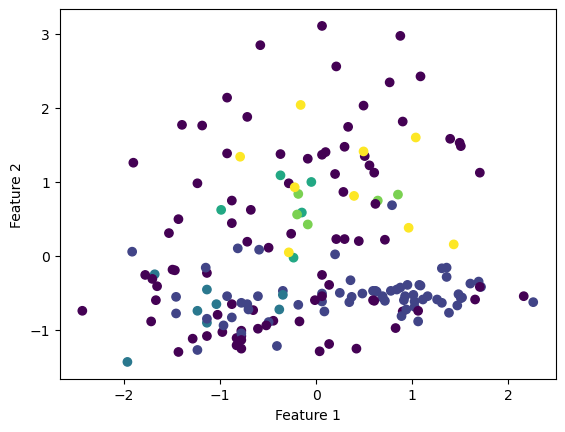

In [15]:
plt.scatter(X[:,0], X[:,1], c=labels)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

In [16]:
clean_X = X[labels != -1]
clean_labels = labels[labels != -1]

if len(clusters) >= 2:
    print("Silhouette Score:", silhouette_score(clean_X, clean_labels))
else:
    print("Not enough clusters")

Silhouette Score: 0.24046128028458877
